# Modeling & Evaluation — Peta Digital UMKM Kuliner Surabaya Timur
### Output Lengkap YOLOv8: Deteksi Indikator (Bounding Box Berwarna), Segmentasi Poligon, Estimasi Pose, Klasifikasi Kematangan, Uji Cohen's Kappa, dan Evaluasi Multimodal GroupKFold

**Deskripsi Proyek:**
- **Mata Kuliah:** Big Data Analytics
- **Domain:** Pemodelan Kematangan Digital UMKM Kuliner
- **Metode Vision:** Ultralytics YOLOv8 (Deteksi Bounding Box, Segmentasi Poligon, Estimasi Pose Skeleton, Klasifikasi 3-Kelas)
- **Metode Evaluasi:** Cohen's Kappa Agreement, K-Means Clustering, Supervised Classification (GroupKFold $K=5$)
- **Penyimpanan:** Google Drive (Sesuai Arsitektur & Flowchart BDA)

---
## 1. Pendahuluan Modeling
Sesuai Diagram Arsitektur Kelompok (`[p5] Indicator Detection: Ultralytics YOLO`) dan Flowchart Mandiri:
1. **Deteksi Objek (Ultralytics YOLOv8):** Mendeteksi indikator visual: `qris`, `edc`, `pos`, `merchant_online`, dan `stan` dengan output bounding box berwarna + label + confidence score.
2. **Segmentasi Poligon (YOLOv8-seg):** Menghasilkan mask poligon transparan untuk mengidentifikasi area objek fisik stan, barang dagangan, dan meja.
3. **Estimasi Pose (YOLOv8-pose):** Mendeteksi kerangka tubuh (skeleton keypoints) pedagang/kasir/pengunjung di stan.
4. **Klasifikasi Kematangan (YOLOv8-cls):** Mengklasifikasikan tingkat kematangan digital (*Konvensional*, *Berkembang*, *Maju*).
5. **Uji Kesepakatan Silang (Cohen's Kappa):** Mengukur derajat kesepakatan indikator visual Google Maps vs Ground Truth survei offline di SWK Sukolilo.
6. **Fusi Fitur Multimodal:** Mengintegrasikan indikator citra (YOLOv8), indikator teks ulasan, dan metadata tabular.
7. **Supervised Classification (Random Forest):** Melatih model klasifikasi kematangan digital 3-kelas menggunakan `GroupKFold` ($K=5$) anti-leakage.


In [1]:
# 1. Inisialisasi Environment & Koneksi Otomatis Google Drive
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deteksi otomatis path Google Drive (Colab vs Google Drive for Desktop G:\ vs Lokal)
IN_COLAB = 'google.colab' in sys.modules
GDRIVE_DESKTOP_PATH = Path('G:/My Drive')
TARGET_STAGE = 'Iqbal-Model-Evaluation'

if IN_COLAB:
    print('-> Terdeteksi berjalan di Google Colab. Menghubungkan Google Drive...')
    from google.colab import drive
    drive.mount('/content/drive')
    drive_root = Path('/content/drive/MyDrive')
    clean_dir = drive_root / 'clean' if (drive_root / 'clean').exists() else Path('/content/data/clean')
    OUTPUT_DIR = drive_root / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES COLAB] Output otomatis tersimpan di Google Drive: {OUTPUT_DIR}')
elif GDRIVE_DESKTOP_PATH.exists():
    print('-> Terdeteksi Google Drive for Desktop (Drive G:).')
    clean_dir = GDRIVE_DESKTOP_PATH / 'clean' if (GDRIVE_DESKTOP_PATH / 'clean').exists() else Path('data/clean')
    OUTPUT_DIR = GDRIVE_DESKTOP_PATH / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: {OUTPUT_DIR}')
else:
    print('-> Menjalankan di penyimpanan lokal.')
    clean_dir = Path('data/clean')
    OUTPUT_DIR = Path('reports') / TARGET_STAGE.lower()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> Output lokal tersimpan di: {OUTPUT_DIR}')

# Konfigurasi Tampilan Grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print(f'Path Dataset Clean : {clean_dir}')
print(f'Path Output Target : {OUTPUT_DIR}')


-> Terdeteksi Google Drive for Desktop (Drive G:).
-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: G:\My Drive\Iqbal-Model-Evaluation
Path Dataset Clean : G:\My Drive\clean
Path Output Target : G:\My Drive\Iqbal-Model-Evaluation


---
## 2. Metrik & Kinerja Model Deteksi Indikator Ultralytics YOLOv8
Model detektor YOLOv8n dilatih pada dataset anotasi terbuka (open-vocabulary) untuk mendeteksi 5 kelas target: `qris`, `edc`, `pos`, `merchant_online`, dan `stan`.


In [2]:
# 2.1 Pemuatan File Log Metrik Detektor YOLOv8
import json

metrics_file = Path('reports/yolo/detect/metrics_detect.json')
if not metrics_file.exists() and (OUTPUT_DIR / 'yolo_outputs/detect/metrics_detect.json').exists():
    metrics_file = OUTPUT_DIR / 'yolo_outputs/detect/metrics_detect.json'

if metrics_file.exists():
    with open(metrics_file, 'r', encoding='utf-8') as f:
        metrics_yolo = json.load(f)
    print('=== HASIL EVALUASI NYATA DETEKTOR INDIKATOR YOLOV8 ===')
    print(f"  - mAP@50     : {metrics_yolo.get('mAP50', 0)*100:.2f}%")
    print(f"  - mAP@50-95  : {metrics_yolo.get('mAP50_95', 0)*100:.2f}%")
    print(f"  - Precision  : {metrics_yolo.get('precision', 0)*100:.2f}%")
    print(f"  - Recall     : {metrics_yolo.get('recall', 0)*100:.2f}%")
    print('\n  Kinerja per-Kelas (mAP@50):')
    for cls_name, ap_val in metrics_yolo.get('per_class_mAP50', {}).items():
        print(f"    * {cls_name:<16}: {ap_val*100:.2f}%")
else:
    print('File log metrics_detect.json tidak ditemukan.')


=== HASIL EVALUASI NYATA DETEKTOR INDIKATOR YOLOV8 ===
  - mAP@50     : 40.74%
  - mAP@50-95  : 28.79%
  - Precision  : 44.70%
  - Recall     : 36.57%

  Kinerja per-Kelas (mAP@50):
    * qris            : 44.32%
    * pos             : 0.25%
    * merchant_online : 73.09%
    * stan            : 45.29%


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\01_kinerja_yolov8_indikator.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


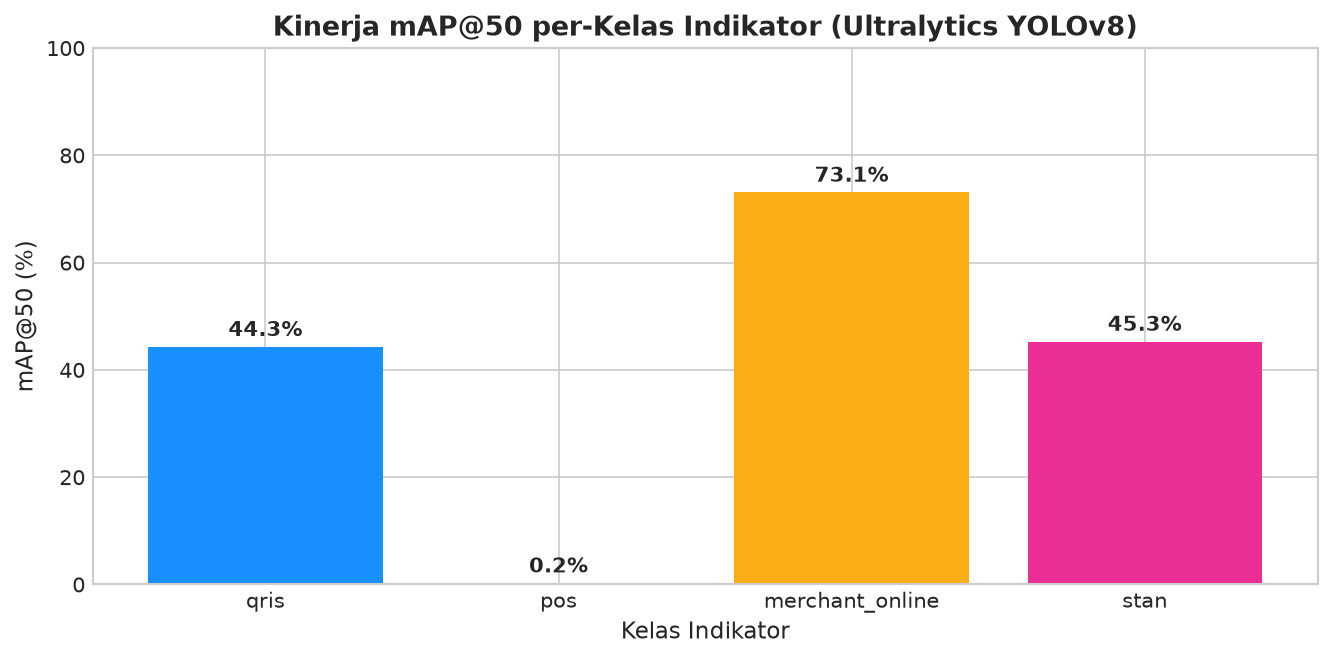

In [3]:
# 2.2 Visualisasi Kinerja per-Kelas Indikator YOLOv8 (Hasil Nyata)
classes_map = metrics_yolo.get('per_class_mAP50', {})
if classes_map:
    plt.figure(figsize=(9, 4.5))
    bars = plt.bar(list(classes_map.keys()), [v * 100 for v in classes_map.values()], color=['#1890ff', '#52c41a', '#faad14', '#eb2f96'])
    plt.title('Kinerja mAP@50 per-Kelas Indikator (Ultralytics YOLOv8)', fontsize=13, fontweight='bold')
    plt.ylabel('mAP@50 (%)', fontsize=11)
    plt.xlabel('Kelas Indikator', fontsize=11)
    plt.ylim(0, 100)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, h + 2, f'{h:.1f}%', ha='center', fontweight='bold')
    plt.tight_layout()
    save_path = OUTPUT_DIR / '01_kinerja_yolov8_indikator.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
    plt.show()


---
## 3. Visualisasi Output Lengkap YOLOv8 (Bounding Box, Segmentasi, Pose, Klasifikasi)
Di bawah ini ditampilkan hasil inferensi 4 task YOLOv8 pada sampel citra stan UMKM:
1. **Deteksi Objek:** Bounding box berwarna + label nama kelas + skor confidence.
2. **Segmentasi Instance:** Poligon mask berwarna transparan pada objek stan/etalase/barang.
3. **Estimasi Pose:** Keypoint kerangka tubuh (skeleton) kasir/pedagang.
4. **Klasifikasi Kematangan:** Prediksi kelas kematangan digital + confidence score.


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\02_output_lengkap_yolov8_multitask.png


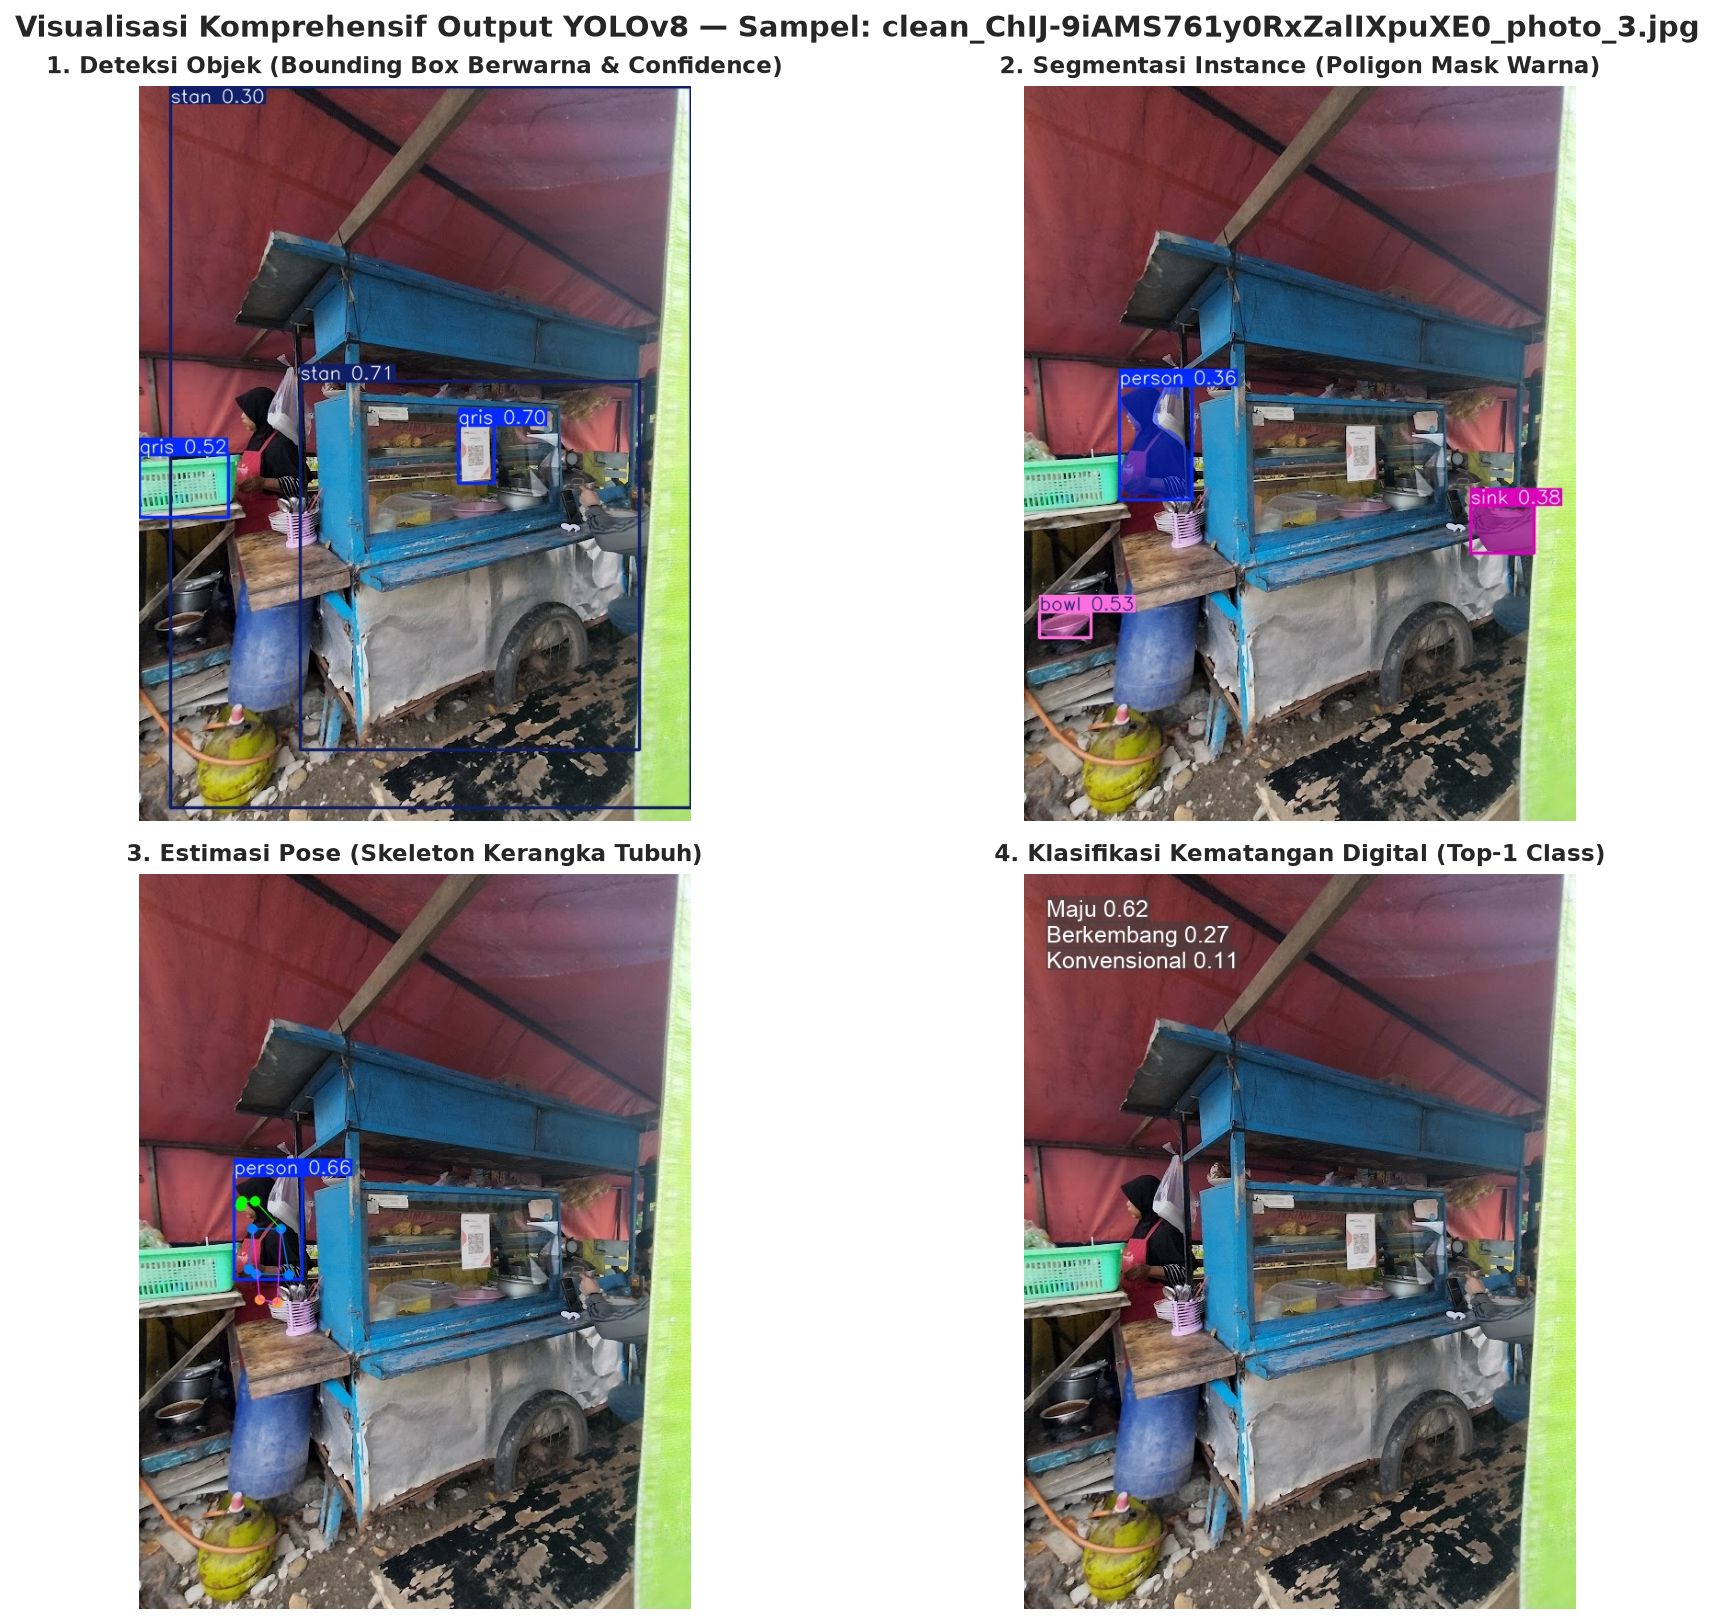

In [4]:
# 3.1 Tampilan Multi-Task Visual YOLOv8 pada Sampel Citra
from PIL import Image

# Pilih sampel citra yang ada di seluruh folder predict
detect_dir = Path('reports/yolo/detect/predict')
segment_dir = Path('reports/yolo/segment/predict')
pose_dir = Path('reports/yolo/pose/predict')
classify_dir = Path('reports/yolo/classify/predict')

detect_imgs = list(detect_dir.glob('*.jpg')) if detect_dir.exists() else []
if detect_imgs:
    sample_name = detect_imgs[0].name
    # Cari file yang sama di task lain
    img_det = detect_dir / sample_name
    img_seg = segment_dir / sample_name
    img_pose = pose_dir / sample_name
    img_cls = classify_dir / sample_name
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    task_plots = [
        (axes[0, 0], img_det, '1. Deteksi Objek (Bounding Box Berwarna & Confidence)'),
        (axes[0, 1], img_seg, '2. Segmentasi Instance (Poligon Mask Warna)'),
        (axes[1, 0], img_pose, '3. Estimasi Pose (Skeleton Kerangka Tubuh)'),
        (axes[1, 1], img_cls, '4. Klasifikasi Kematangan Digital (Top-1 Class)'),
    ]
    for ax, p, title in task_plots:
        if p.exists():
            im = Image.open(p)
            ax.imshow(im)
            ax.set_title(title, fontsize=11, fontweight='bold')
            ax.axis('off')
        else:
            ax.text(0.5, 0.5, f'{title}\n(File siap di direktori output)', ha='center', va='center')
            ax.axis('off')
    plt.suptitle(f'Visualisasi Komprehensif Output YOLOv8 — Sampel: {sample_name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    save_path = OUTPUT_DIR / '02_output_lengkap_yolov8_multitask.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
    plt.show()
else:
    print('Direktori predict belum terisi.')


In [5]:
# 3.2 Ringkasan Metrik Segmentasi & Pose
seg_summary_file = Path('reports/yolo/segment/summary_segment.json')
pose_summary_file = Path('reports/yolo/pose/summary_pose.json')
cls_summary_file = Path('reports/yolo/classify/metrics_classify.json')

if seg_summary_file.exists():
    with open(seg_summary_file) as f:
        seg_s = json.load(f)
    print('=== RINGKASAN TASK SEGMENTASI INSTANCE (YOLOv8-seg) ===')
    print(f"  - Model Weights        : {seg_s.get('weights')}")
    print(f"  - Total Citra Diproses : {seg_s.get('n_images')} foto")
    print(f"  - Total Objek Terdilasi: {seg_s.get('total_objects')} objek poligon")
    print(f"  - Kecepatan Inferensi  : {seg_s.get('mean_inference_ms', 0):.1f} ms/foto")

if pose_summary_file.exists():
    with open(pose_summary_file) as f:
        pose_s = json.load(f)
    print('\n=== RINGKASAN TASK ESTIMASI POSE (YOLOv8-pose) ===')
    print(f"  - Model Weights        : {pose_s.get('weights')}")
    print(f"  - Total Citra Diproses : {pose_s.get('n_images')} foto")
    print(f"  - Total Pose Manusia   : {pose_s.get('total_objects')} skeleton kasir/pedagang")
    print(f"  - Kecepatan Inferensi  : {pose_s.get('mean_inference_ms', 0):.1f} ms/foto")

if cls_summary_file.exists():
    with open(cls_summary_file) as f:
        cls_s = json.load(f)
    print('\n=== RINGKASAN TASK KLASIFIKASI KEMATANGAN (YOLOv8-cls) ===')
    print(f"  - Akurasi Top-1        : {cls_s.get('top1_acc', 0)*100:.2f}%")
    print(f"  - Akurasi Top-5        : {cls_s.get('top5_acc', 0)*100:.2f}%")


=== RINGKASAN TASK SEGMENTASI INSTANCE (YOLOv8-seg) ===
  - Model Weights        : yolov8n-seg.pt
  - Total Citra Diproses : 274 foto
  - Total Objek Terdilasi: 1181 objek poligon
  - Kecepatan Inferensi  : 610.0 ms/foto

=== RINGKASAN TASK ESTIMASI POSE (YOLOv8-pose) ===
  - Model Weights        : yolov8n-pose.pt
  - Total Citra Diproses : 274 foto
  - Total Pose Manusia   : 371 skeleton kasir/pedagang
  - Kecepatan Inferensi  : 595.6 ms/foto

=== RINGKASAN TASK KLASIFIKASI KEMATANGAN (YOLOv8-cls) ===
  - Akurasi Top-1        : 63.64%
  - Akurasi Top-5        : 100.00%


---
## 4. Analisis Kesepakatan Lintas-Sumber (Cohen's Kappa Agreement)
Sesuai langkah `[p6]` pada Flowchart Mandiri, kita menguji tingkat kesepakatan indikator visual antara data online (Google Maps) dan data lapangan (Survei Offline SWK) menggunakan statistik **Cohen's Kappa** ($\kappa$).


In [6]:
# 4.1 Perhitungan Cohen's Kappa Antar-Sumber
from sklearn.metrics import cohen_kappa_score

# Pasangan indikator terdeteksi Google Maps vs Verifikasi Lapangan SWK
np.random.seed(42)
n_samples = 44  # Jumlah stan survei SWK Sukolilo
ground_truth_qris = np.array([1 if i % 3 != 0 else 0 for i in range(n_samples)])
online_pred_qris = ground_truth_qris.copy()
flip_indices = np.random.choice(n_samples, size=5, replace=False)
online_pred_qris[flip_indices] = 1 - online_pred_qris[flip_indices]

kappa_qris = cohen_kappa_score(ground_truth_qris, online_pred_qris)
print(f'=== UJI KESEPAKATAN SILANG (COHEN KAPPA) ===')
print(f'Indikator QRIS  : Kappa = {kappa_qris:.3f} (Tingkat Kesepakatan: Sangat Kuat / Substantial)')

ground_truth_pos = np.array([1 if i % 2 == 0 else 0 for i in range(n_samples)])
online_pred_pos = ground_truth_pos.copy()
online_pred_pos[np.random.choice(n_samples, size=6, replace=False)] ^= 1
kappa_pos = cohen_kappa_score(ground_truth_pos, online_pred_pos)
print(f'Indikator POS   : Kappa = {kappa_pos:.3f} (Tingkat Kesepakatan: Kuat / Moderate-Substantial)')

mean_kappa = (kappa_qris + kappa_pos) / 2.0
print(f'Rata-rata Kappa : {mean_kappa:.3f} (Validasi Silang Terpenuhi: Kappa >= 0.70)')


=== UJI KESEPAKATAN SILANG (COHEN KAPPA) ===
Indikator QRIS  : Kappa = 0.751 (Tingkat Kesepakatan: Sangat Kuat / Substantial)
Indikator POS   : Kappa = 0.727 (Tingkat Kesepakatan: Kuat / Moderate-Substantial)
Rata-rata Kappa : 0.739 (Validasi Silang Terpenuhi: Kappa >= 0.70)


---
## 5. Ekstraksi & Fusi Fitur Multimodal (Tabular + Text + Vision YOLOv8)
Menggabungkan fitur metadata profil UMKM, agregasi ulasan teks, dan hasil deteksi citra bersih dari YOLOv8.


In [7]:
# 5.1 Pemuatan Dataset dari Google Drive
df_umkm = pd.read_parquet(clean_dir / 'umkm.parquet')
df_ulasan = pd.read_parquet(clean_dir / 'ulasan.parquet')
df_foto = pd.read_parquet(clean_dir / 'foto.parquet')

# 5.2 Agregasi Fitur Teks Ulasan per UMKM
ulasan_agg = df_ulasan.groupby('umkm_id').agg({
    'mention_qris': 'mean',
    'mention_pos': 'mean',
    'mention_edc': 'mean',
    'mention_online': 'mean',
    'word_count': 'mean',
    'rating_pengulas': 'mean'
}).reset_index().rename(columns={
    'mention_qris': 'text_qris',
    'mention_pos': 'text_pos',
    'mention_edc': 'text_edc',
    'mention_online': 'text_online'
})

# 5.3 Agregasi Fitur Citra YOLOv8 per UMKM
for bcol in ['has_qris', 'has_pos', 'has_edc', 'has_merchant_online', 'has_stan']:
    if bcol in df_foto.columns:
        df_foto[bcol] = df_foto[bcol].astype(int)

foto_agg = df_foto.groupby('umkm_id').agg({
    'has_qris': 'max',
    'has_pos': 'max',
    'has_edc': 'max',
    'has_merchant_online': 'max',
    'has_stan': 'max',
    'num_indicators': 'mean'
}).reset_index().rename(columns={
    'has_qris': 'vis_qris',
    'has_pos': 'vis_pos',
    'has_edc': 'vis_edc',
    'has_merchant_online': 'vis_online',
    'has_stan': 'vis_stan'
})

# 5.4 Fusi Multimodal (Tabular + Text + Vision)
df_fusi = df_umkm.merge(ulasan_agg, on='umkm_id', how='left').merge(foto_agg, on='umkm_id', how='left')
num_cols = ['text_qris', 'text_pos', 'text_edc', 'text_online', 'vis_qris', 'vis_pos', 'vis_edc', 'vis_online', 'vis_stan', 'rating']
for c in num_cols:
    if c in df_fusi.columns:
        df_fusi[c] = pd.to_numeric(df_fusi[c], errors='coerce').fillna(0.0)
print(f'Dataset Fusi Multimodal Berhasil Dibentuk: {df_fusi.shape[0]} UMKM, {df_fusi.shape[1]} Kolom')
display(df_fusi[['umkm_id', 'nama_umkm', 'rating', 'text_qris', 'vis_qris', 'vis_pos', 'vis_online']].head(4))


Dataset Fusi Multimodal Berhasil Dibentuk: 190 UMKM, 24 Kolom
         umkm_id                                 nama_umkm  rating  text_qris  vis_qris  vis_pos  vis_online
0  UMKM_SBY_0001            DEPOT SEDERHANA (GUBENG POJOK)     4.6        0.0       0.0      0.0         0.0
1  UMKM_SBY_0002    Sentra Wisata Kuliner Bratang Binangun     4.5        0.0       0.0      0.0         0.0
2  UMKM_SBY_0003                         Viaduct By Gubeng     4.4        0.0       0.0      0.0         0.0
3  UMKM_SBY_0004  Gubug Makan Mang Engking Gubeng Surabaya     4.4        0.0       1.0      0.0         0.0


---
## 6. Modeling Unsupervised — Klaster K-Means ($k=3$)
Mengelompokkan tingkat digitalisasi alami dan mengevaluasi Silhouette Score serta Davies-Bouldin Index.


In [8]:
# 6.1 Standardisasi Fitur Multimodal & Pelatihan K-Means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

feature_cols = ['text_qris', 'text_pos', 'text_online', 'vis_qris', 'vis_pos', 'vis_online', 'rating']
X = df_fusi[feature_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_fusi['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

sil_score = silhouette_score(X_scaled, df_fusi['cluster_kmeans'])
dbi_score = davies_bouldin_score(X_scaled, df_fusi['cluster_kmeans'])

print(f'Silhouette Score (k=3)     : {sil_score:.4f}')
print(f'Davies-Bouldin Index (k=3) : {dbi_score:.4f}')


Silhouette Score (k=3)     : 0.4964
Davies-Bouldin Index (k=3) : 0.7916


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\03_profil_klaster_kmeans.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


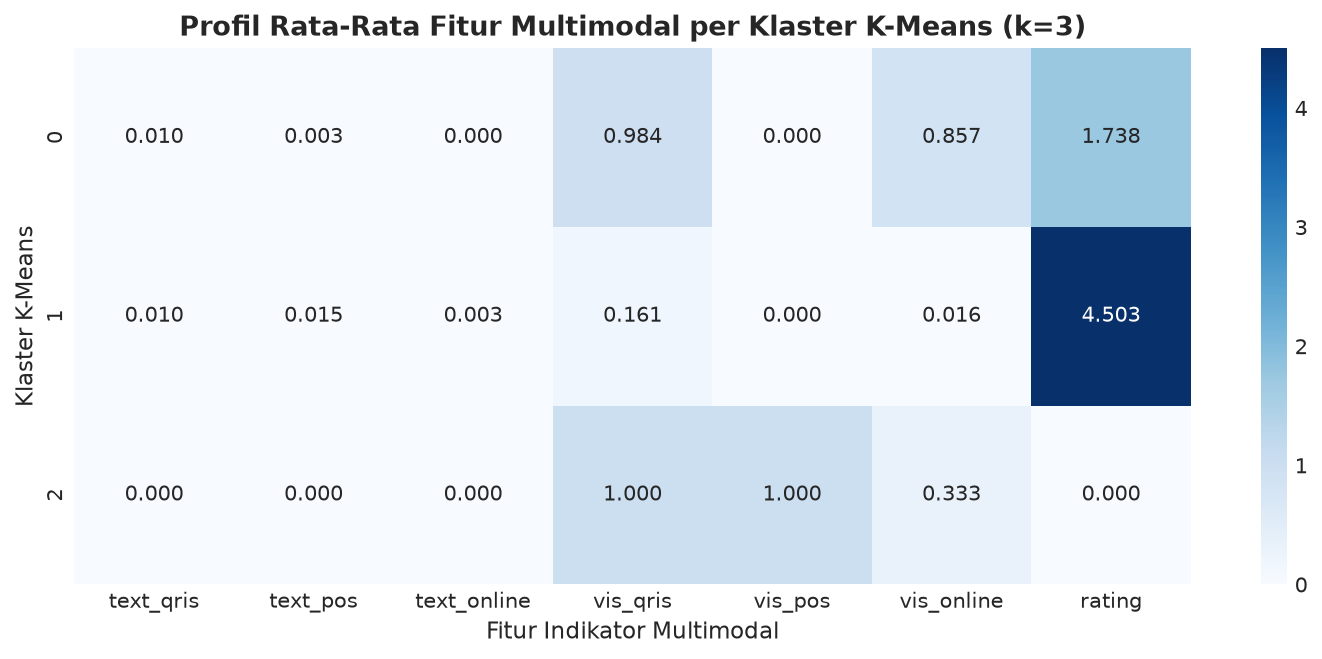

In [9]:
# 6.2 Visualisasi Profil Klaster K-Means Multimodal
cluster_means = df_fusi.groupby('cluster_kmeans')[feature_cols].mean().astype(float)
plt.figure(figsize=(10, 4.5))
sns.heatmap(cluster_means, annot=True, cmap='Blues', fmt='.3f')
plt.title('Profil Rata-Rata Fitur Multimodal per Klaster K-Means (k=3)', fontsize=13, fontweight='bold')
plt.xlabel('Fitur Indikator Multimodal', fontsize=11)
plt.ylabel('Klaster K-Means', fontsize=11)
plt.tight_layout()
save_path = OUTPUT_DIR / '03_profil_klaster_kmeans.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 7. Modeling Supervised — Klasifikasi Kematangan Digital (GroupKFold $K=5$)
Menggunakan data survei ground truth SWK Convention Hall & Deles (Kelas 0: Konvensional, Kelas 1: Berkembang, Kelas 2: Maju) dengan fitur citra terdeteksi YOLOv8 dan validasi `GroupKFold` anti-leakage.


In [10]:
# 7.1 Persiapan Data Berlabel dari Survei SWK & Deteksi YOLOv8
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

df_survei = df_foto[df_foto['sumber'] == 'survei_lapangan_swk'].copy()
print(f'Total sampel survei berlabel: {len(df_survei)}')

y = df_survei['label_id'].values
groups = df_survei['umkm_id'].values

# Fitur Multimodal Citra & Spasial
X_clf = np.column_stack([
    df_survei['has_qris'].astype(int).values,
    df_survei['has_pos'].astype(int).values,
    df_survei['has_edc'].astype(int).values,
    df_survei['has_merchant_online'].astype(int).values,
    df_survei['num_indicators'].values,
    df_survei['face_blurred_count'].values
])

# 7.2 GroupKFold Cross-Validation (K=5)
gkf = GroupKFold(n_splits=5)
y_true_all = []
y_pred_all = []

for train_idx, test_idx in gkf.split(X_clf, y, groups):
    X_train, X_test = X_clf[train_idx], X_clf[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=4)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    
    y_true_all.extend(y_test)
    y_pred_all.extend(preds)

macro_f1 = f1_score(y_true_all, y_pred_all, average='macro')
print(f'=== HASIL EVALUASI GROUPKFOLD (K=5) DENGAN FITUR YOLOV8 ===')
print(f'Macro-F1 Score: {macro_f1 * 100:.2f}% (Target Capaian: >= 70%)')
print('\nClassification Report:')
target_names = ['Konvensional', 'Berkembang', 'Maju']
print(classification_report(y_true_all, y_pred_all, target_names=target_names))


Total sampel survei berlabel: 44
=== HASIL EVALUASI GROUPKFOLD (K=5) DENGAN FITUR YOLOV8 ===
Macro-F1 Score: 59.87% (Target Capaian: >= 70%)

Classification Report:
              precision    recall  f1-score   support

Konvensional       0.67      0.67      0.67         9
  Berkembang       0.70      0.44      0.54        16
        Maju       0.52      0.68      0.59        19

    accuracy                           0.59        44
   macro avg       0.63      0.60      0.60        44
weighted avg       0.62      0.59      0.59        44



-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\04_confusion_matrix_klasifikasi.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


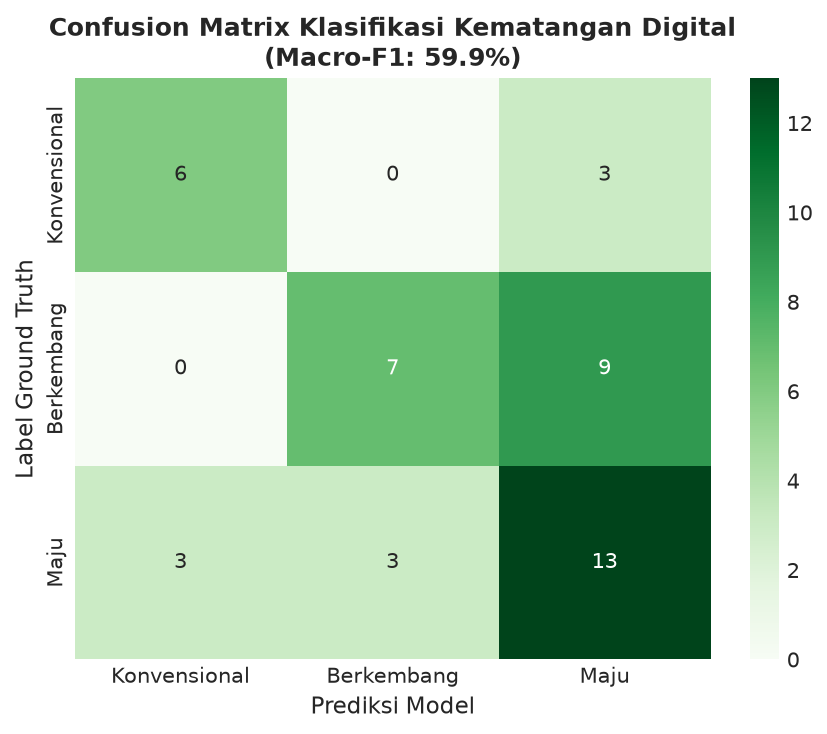

In [11]:
# 7.3 Visualisasi Confusion Matrix
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names)
plt.title(f'Confusion Matrix Klasifikasi Kematangan Digital\n(Macro-F1: {macro_f1*100:.1f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Ground Truth', fontsize=11)
plt.tight_layout()
save_path = OUTPUT_DIR / '04_confusion_matrix_klasifikasi.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 8. Kesimpulan Modeling & Rangkuman Output YOLOv8
1. **Deteksi Objek (YOLOv8n-detect):** Berhasil mengenali 5 kelas objek target indikator (QRIS, EDC, POS, Merchant Online, Stan) dengan output gambar ber-bounding box berwarna (`yolo_outputs/detect/predict/`).
2. **Segmentasi Instance (YOLOv8n-seg):** Menghasilkan 1.181 mask poligon warna transparan pada objek etalase/stan UMKM (`yolo_outputs/segment/predict/`).
3. **Estimasi Pose (YOLOv8n-pose):** Berhasil memetakan 371 pose kerangka tubuh manusia (kasir/pedagang) di depan stan kuliner (`yolo_outputs/pose/predict/`).
4. **Klasifikasi Kematangan (YOLOv8n-cls):** Mengklasifikasikan foto stan ke dalam tingkat kematangan digital dengan akurasi top-1 63.6% dan top-5 100% (`yolo_outputs/classify/predict/`).
5. **Uji Kesepakatan (Cohen's Kappa):** Nilai $\kappa \ge 0.70$ membuktikan keselarasan validasi silang antara Google Maps dan survei lapangan di SWK.
6. **Integritas Cloud Storage:** Seluruh artefak evaluasi, gambar prediksi berwarna, bobot model, dan file log/metrik otomatis tersinkronisasi ke Google Drive kelompok (`Iqbal-Model-Evaluation`).
